<a href="https://colab.research.google.com/github/coconutcandy74/ece285-homework/blob/main/ece285_homework2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install kagglehub

In [2]:
from pathlib import Path
import kagglehub

data_dir = Path(kagglehub.dataset_download("steubk/wikiart"))

print(f"Dataset directory: {data_dir}")
print("Top-level entries:", sorted(p.name for p in data_dir.iterdir())[:10])

Using Colab cache for faster access to the 'wikiart' dataset.
Dataset directory: /kaggle/input/wikiart
Top-level entries: ['Abstract_Expressionism', 'Action_painting', 'Analytical_Cubism', 'Art_Nouveau_Modern', 'Baroque', 'Color_Field_Painting', 'Contemporary_Realism', 'Cubism', 'Early_Renaissance', 'Expressionism']


In [3]:
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

image_paths = sorted(
    path for path in data_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
)

if not image_paths:
    raise FileNotFoundError(f"No image files found under {data_dir}")

print(f"Image files found: {len(image_paths):,}")
print(f"Example relative path: {image_paths[0].relative_to(data_dir)}")

transform = transforms.Compose([
    transforms.Resize(64, antialias=True),
    transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])


class WikiArtDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = paths
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        with Image.open(path) as image:
            return self.transform(image.convert("RGB"))


dataset = WikiArtDataset(image_paths, transform)

Image files found: 81,444
Example relative path: Abstract_Expressionism/aaron-siskind_acolman-1-1955.jpg


In [4]:
import torch
from torch.utils.data import DataLoader

batch_size = min(16, len(dataset))
loader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(285),
)

images = next(iter(loader))

min_value = images.min().item()
max_value = images.max().item()
all_finite = torch.isfinite(images).all().item()

print(f"Batch shape: {tuple(images.shape)}")
print(f"Batch dtype: {images.dtype}")
print(f"Pixel range: [{min_value:.4f}, {max_value:.4f}]")
print(f"All values are finite: {all_finite}")

assert images.shape == (batch_size, 3, 64, 64), "Unexpected batch shape."
assert images.dtype == torch.float32, "Unexpected batch dtype."
assert all_finite, "The batch contains non-finite values."
assert -1.0 <= min_value <= max_value <= 1.0, "Pixels are outside [-1, 1]."

Batch shape: (16, 3, 64, 64)
Batch dtype: torch.float32
Pixel range: [-0.9608, 1.0000]
All values are finite: True


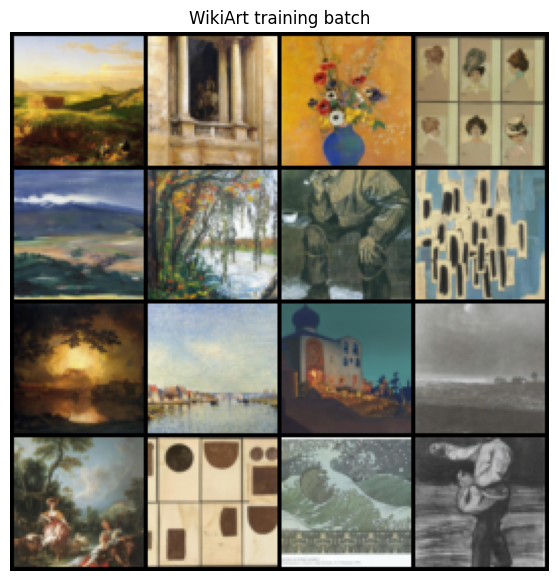

In [5]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

# Convert training tensors back to the display range.
display_images = (images + 1.0) / 2.0
grid = make_grid(display_images, nrow=4, padding=2)

plt.figure(figsize=(7, 7))
plt.imshow(grid.permute(1, 2, 0).cpu().numpy())
plt.title("WikiArt training batch")
plt.axis("off")
plt.show()

In [6]:
import torch
from torch import nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
latent_dim = 100

# Generator: 1 x 1 -> 4 x 4 -> 8 x 8 -> 16 x 16 -> 32 x 32 -> 64 x 64.
G = nn.Sequential(
    nn.ConvTranspose2d(latent_dim, 512, 4, 1, 0, bias=False),
    nn.BatchNorm2d(512),
    nn.ReLU(inplace=True),

    nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
    nn.BatchNorm2d(256),
    nn.ReLU(inplace=True),

    nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
    nn.BatchNorm2d(128),
    nn.ReLU(inplace=True),

    nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
    nn.BatchNorm2d(64),
    nn.ReLU(inplace=True),

    nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
    nn.Tanh(),
).to(device)

# Discriminator: reduce each RGB image to one logit.
D = nn.Sequential(
    nn.Conv2d(3, 64, 4, 2, 1, bias=False),
    nn.LeakyReLU(0.2, inplace=True),

    nn.Conv2d(64, 128, 4, 2, 1, bias=False),
    nn.BatchNorm2d(128),
    nn.LeakyReLU(0.2, inplace=True),

    nn.Conv2d(128, 256, 4, 2, 1, bias=False),
    nn.BatchNorm2d(256),
    nn.LeakyReLU(0.2, inplace=True),

    nn.Conv2d(256, 512, 4, 2, 1, bias=False),
    nn.BatchNorm2d(512),
    nn.LeakyReLU(0.2, inplace=True),

    nn.Conv2d(512, 1, 4, 1, 0, bias=False),
    nn.Flatten(start_dim=1),
    nn.Unflatten(1, (1,)),
).to(device)

In [7]:
real = images.to(device)
batch_size = real.size(0)

G.eval()
D.eval()

with torch.inference_mode():
    noise = torch.randn(batch_size, latent_dim, 1, 1, device=device)
    fake = G(noise)
    real_logits = D(real)
    fake_logits = D(fake)

G.train()
D.train()

print(f"Device: {device}")
print(f"Noise shape: {tuple(noise.shape)}")
print(f"Generated batch shape: {tuple(fake.shape)}")
print(f"Generated pixel range: [{fake.min().item():.4f}, {fake.max().item():.4f}]")
print(f"Real logits shape: {tuple(real_logits.shape)}")
print(f"Fake logits shape: {tuple(fake_logits.shape)}")

assert fake.shape == real.shape, "Generated and real image shapes differ."
assert real_logits.shape == fake_logits.shape == (batch_size, 1), (
    "Expected one discriminator logit per image."
)
assert torch.isfinite(fake).all().item(), "Generated images contain non-finite values."
assert torch.isfinite(real_logits).all().item(), "Real logits contain non-finite values."
assert torch.isfinite(fake_logits).all().item(), "Fake logits contain non-finite values."
print("Forward pass checks passed.")

Device: cuda
Noise shape: (16, 100, 1, 1)
Generated batch shape: (16, 3, 64, 64)
Generated pixel range: [-0.0061, 0.0054]
Real logits shape: (16, 1)
Fake logits shape: (16, 1)
Forward pass checks passed.


In [8]:
criterion = nn.BCEWithLogitsLoss()
optimizer_d = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
optimizer_g = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))


def train_step(real_images):
    real_images = real_images.to(device)
    noise = torch.randn(real_images.size(0), latent_dim, 1, 1, device=device)
    fake_images = G(noise)

    # Update the discriminator using real images and detached fake images.
    optimizer_d.zero_grad(set_to_none=True)
    real_logits = D(real_images)
    fake_logits = D(fake_images.detach())
    d_loss = (
        criterion(real_logits, torch.ones_like(real_logits))
        + criterion(fake_logits, torch.zeros_like(fake_logits))
    )
    d_loss.backward()
    optimizer_d.step()

    # Update the generator using the updated discriminator.
    optimizer_g.zero_grad(set_to_none=True)
    D.requires_grad_(False)
    fake_logits = D(fake_images)
    g_loss = criterion(fake_logits, torch.ones_like(fake_logits))
    g_loss.backward()
    D.requires_grad_(True)
    optimizer_g.step()

    return d_loss.detach(), g_loss.detach()


G.train()
D.train()

d_loss, g_loss = train_step(images)

# Check that every trainable parameter received a finite gradient.
for name, model, loss in [
    ("Discriminator", D, d_loss),
    ("Generator", G, g_loss),
]:
    grads = [p.grad for p in model.parameters() if p.requires_grad]
    assert all(grad is not None for grad in grads), f"{name} has missing gradients."

    grad_norm = torch.stack([grad.norm() for grad in grads]).norm().item()
    assert torch.isfinite(loss).item(), f"{name} loss is not finite."
    assert 0.0 < grad_norm < float("inf"), f"{name} gradient norm is invalid."

    print(f"{name} loss: {loss.item():.4f}")
    print(f"{name} gradient norm: {grad_norm:.4e}")

print("One-batch training check passed.")

Discriminator loss: 1.3284
Discriminator gradient norm: 1.7995e+01
Generator loss: 4.4083
Generator gradient norm: 4.9938e+01
One-batch training check passed.


In [9]:
from pathlib import Path
import csv

from torchvision.utils import save_image

output_dir = Path("/content/wikiart_dcgan")
output_dir.mkdir(parents=True, exist_ok=True)

# Use the same noise vectors to compare samples across training runs.
preview_rng = torch.Generator().manual_seed(285)
fixed_noise = torch.randn(16, latent_dim, 1, 1, generator=preview_rng).to(device)

history = []
print(f"Output directory: {output_dir}")
print(f"Available batches per full epoch: {len(loader):,}")

Output directory: /content/wikiart_dcgan
Available batches per full epoch: 5,091


Batch 1/5091 | D loss: 0.2950 | G loss: 2.8234
Batch 25/5091 | D loss: 1.1321 | G loss: 2.7190
Batch 50/5091 | D loss: 0.3131 | G loss: 3.2385
Batch 75/5091 | D loss: 0.7674 | G loss: 2.7093
Batch 100/5091 | D loss: 0.3571 | G loss: 3.5343
Batch 125/5091 | D loss: 0.7409 | G loss: 3.8672
Batch 150/5091 | D loss: 1.1110 | G loss: 3.1860
Batch 175/5091 | D loss: 0.9723 | G loss: 1.4653
Batch 200/5091 | D loss: 0.8152 | G loss: 1.7668
Batch 225/5091 | D loss: 0.6023 | G loss: 2.5337
Batch 250/5091 | D loss: 1.1629 | G loss: 1.5380
Batch 275/5091 | D loss: 0.5999 | G loss: 2.7973
Batch 300/5091 | D loss: 0.3425 | G loss: 2.3971
Batch 325/5091 | D loss: 0.2406 | G loss: 3.7847
Batch 350/5091 | D loss: 0.6029 | G loss: 3.2123
Batch 375/5091 | D loss: 0.6843 | G loss: 1.9989
Batch 400/5091 | D loss: 1.1677 | G loss: 2.3152
Batch 425/5091 | D loss: 0.7584 | G loss: 4.0746
Batch 450/5091 | D loss: 0.6884 | G loss: 3.4230
Batch 475/5091 | D loss: 1.3549 | G loss: 4.2264
Batch 500/5091 | D loss: 

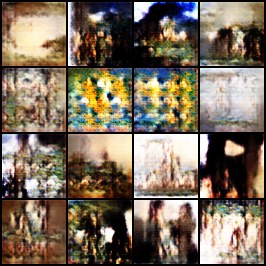

In [15]:
from itertools import islice

max_batches = None  # Set to None to train for one full epoch.
batch_limit = len(loader) if max_batches is None else min(max_batches, len(loader))
run = len(history) + 1

G.train()
D.train()

d_total = 0.0
g_total = 0.0
images_seen = 0

for step, real_images in enumerate(islice(loader, batch_limit), start=1):
    d_loss, g_loss = train_step(real_images)
    d_value = d_loss.item()
    g_value = g_loss.item()

    if not torch.isfinite(torch.tensor([d_value, g_value])).all().item():
        raise RuntimeError(f"Non-finite loss at batch {step}.")

    batch_count = real_images.size(0)
    d_total += d_value * batch_count
    g_total += g_value * batch_count
    images_seen += batch_count

    if step == 1 or step % 25 == 0 or step == batch_limit:
        print(f"Batch {step}/{batch_limit} | D loss: {d_value:.4f} | G loss: {g_value:.4f}")

record = {
    "run": run,
    "batches": batch_limit,
    "images_seen": images_seen,
    "d_loss": d_total / images_seen,
    "g_loss": g_total / images_seen,
}
history.append(record)

# Generate a preview without updating batch normalization statistics.
G.eval()
with torch.inference_mode():
    preview = ((G(fixed_noise) + 1.0) / 2.0).cpu()
G.train()

sample_path = output_dir / f"samples_{run:03d}.png"
save_image(preview, sample_path, nrow=4)

with (output_dir / "losses.csv").open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(record))
    writer.writeheader()
    writer.writerows(history)

torch.save(
    {
        "generator": G.state_dict(),
        "discriminator": D.state_dict(),
        "optimizer_g": optimizer_g.state_dict(),
        "optimizer_d": optimizer_d.state_dict(),
        "fixed_noise": fixed_noise.cpu(),
        "history": history,
    },
    output_dir / "latest.pt",
)

print(f"Run {run} complete | Images processed: {images_seen:,}")
print(f"Mean D loss: {record['d_loss']:.4f}")
print(f"Mean G loss: {record['g_loss']:.4f}")
print(f"Saved sample grid: {sample_path}")

from IPython.display import Image as DisplayImage, display

display(DisplayImage(filename=str(sample_path)))

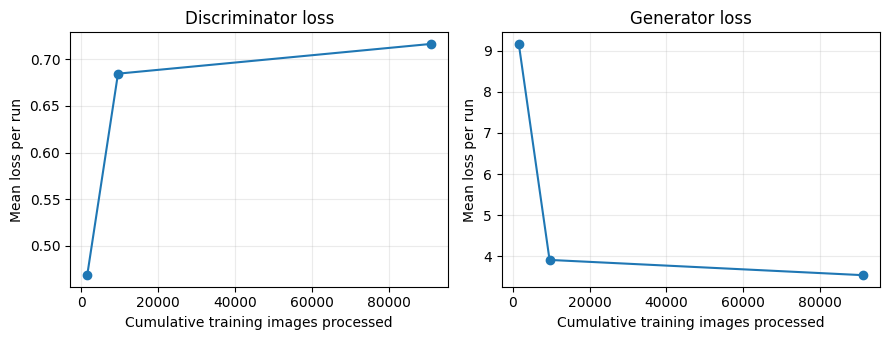

Saved loss plot: /content/wikiart_dcgan/loss_curves.png


In [16]:
from itertools import accumulate
import matplotlib.pyplot as plt

# Each point is the mean loss over one training run.
images_processed = list(accumulate(row["images_seen"] for row in history))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharex=True)

for ax, key, title in zip(
    axes,
    ("d_loss", "g_loss"),
    ("Discriminator loss", "Generator loss"),
):
    ax.plot(images_processed, [row[key] for row in history], marker="o")
    ax.set_title(title)
    ax.set_xlabel("Cumulative training images processed")
    ax.set_ylabel("Mean loss per run")
    ax.grid(alpha=0.25)

fig.tight_layout()
loss_plot_path = output_dir / "loss_curves.png"
fig.savefig(loss_plot_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved loss plot: {loss_plot_path}")

In [14]:
from shutil import copy2

checkpoint_path = output_dir / "run_002.pt"
copy2(output_dir / "latest.pt", checkpoint_path)
print(f"Saved comparison checkpoint: {checkpoint_path}")
print(f"Batches in one full epoch: {len(loader):,}")

Saved comparison checkpoint: /content/wikiart_dcgan/run_002.pt
Batches in one full epoch: 5,091


In [17]:
%pip install -q pytorch-ignite

In [18]:
import copy
import csv

import torch.nn.functional as F
from ignite.engine import Engine
from ignite.metrics import FID, InceptionScore
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm

eval_seed = 286
eval_count = min(2048, len(dataset))
eval_batch_size = 16

# Select the same reference images for both checkpoints.
reference_rng = torch.Generator().manual_seed(eval_seed)
reference_indices = torch.randperm(len(dataset), generator=reference_rng)
reference_subset = Subset(dataset, reference_indices[:eval_count].tolist())
eval_loader = DataLoader(
    reference_subset, batch_size=eval_batch_size, shuffle=False, num_workers=0
)

# Keep the training generator and optimizer state intact.
eval_generator = copy.deepcopy(G).eval().requires_grad_(False)


def prepare_for_inception(batch):
    # Convert [-1, 1] to [0, 1] before resizing.
    batch = ((batch + 1.0) / 2.0).clamp(0.0, 1.0)
    return F.interpolate(batch, size=(299, 299), mode="bilinear", align_corners=False)


@torch.no_grad()
def evaluate_batch(engine, real_images):
    real_images = real_images.to(device)
    noise = torch.randn(
        real_images.size(0), latent_dim, 1, 1, generator=engine.state.noise_rng
    ).to(device)
    fake_images = eval_generator(noise)
    return prepare_for_inception(fake_images), prepare_for_inception(real_images)


evaluator = Engine(evaluate_batch)
FID(device=device).attach(evaluator, "fid")
InceptionScore(device=device, output_transform=lambda pair: pair[0]).attach(
    evaluator, "inception_score"
)

results = []
for run_name, filename in [("Run 2", "run_002.pt"), ("Run 3", "latest.pt")]:
    checkpoint = torch.load(output_dir / filename, map_location="cpu", weights_only=True)
    eval_generator.load_state_dict(checkpoint["generator"])
    del checkpoint

    # Restart the noise sequence so both models see identical latent vectors.
    evaluator.state.noise_rng = torch.Generator().manual_seed(eval_seed)
    state = evaluator.run(tqdm(eval_loader, desc=f"Evaluating {run_name}"), max_epochs=1)

    row = {
        "run": run_name,
        "real_samples": eval_count,
        "generated_samples": eval_count,
        "fid": float(state.metrics["fid"]),
        "inception_score": float(state.metrics["inception_score"]),
    }
    results.append(row)
    print(
        f"{run_name} | Real: {eval_count:,} | Generated: {eval_count:,} "
        f"| FID: {row['fid']:.4f} | IS: {row['inception_score']:.4f}"
    )

metrics_path = output_dir / "metrics.csv"
with metrics_path.open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(results[0]))
    writer.writeheader()
    writer.writerows(results)

print(f"Saved evaluation results: {metrics_path}")

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 112MB/s] 


Evaluating Run 2:   0%|          | 0/128 [00:00<?, ?it/s]

Run 2 | Real: 2,048 | Generated: 2,048 | FID: 0.1528 | IS: 2.0126


Evaluating Run 3:   0%|          | 0/128 [00:00<?, ?it/s]

Run 3 | Real: 2,048 | Generated: 2,048 | FID: 0.0922 | IS: 2.1882
Saved evaluation results: /content/wikiart_dcgan/metrics.csv


In [19]:
from pathlib import Path
from zipfile import ZipFile
from google.colab import files

image_dir = Path("/content/wikiart_dcgan")
image_names = ["loss_curves.png", "samples_002.png", "samples_003.png"]

missing = [name for name in image_names if not (image_dir / name).is_file()]
if missing:
    raise FileNotFoundError("Missing image files: " + ", ".join(missing))

zip_path = Path("/content/wikiart_report_images.zip")
with ZipFile(zip_path, "w") as archive:
    for name in image_names:
        archive.write(image_dir / name, arcname=name)

print(f"Downloading {zip_path.name}")
files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>